# REPD — Full pipeline, 1 Jul 2025 → latest update

A before/after view of **every project with a dated event since 1 Jul 2025**: where it stood on that day and where it stands at the latest REPD update.
Unlike `02_pipeline_sankey`, which follows one forward path per project, this includes projects that were already mid-pipeline (in planning, refused, under construction) and shows every move, including refusals overturned on appeal and resubmissions.

**How stage is worked out:** a project's stage on a date is the most recent dated REPD event on or before that date (submitted, granted, appeal granted, refused, appeal lodged, withdrawn, under construction, operational). No stage is assumed from the current status, so a project refused and later granted on appeal moves Refused → Awaiting construction.

**Included:** all statuses, including Revised. Projects first submitted after 1 Jul 2025 start as *Not yet submitted*.

In [1]:
from pathlib import Path

import pandas as pd

from repd.processor import REPDProcessor
from repd.visualise import plot_alluvial

REPD_CSV = Path("../data/REPD_Publication_Q2_2026.csv")
SNAPSHOT = pd.Timestamp("2025-07-01")

## 1. Load and build the cohort

In [2]:
processor = REPDProcessor(REPD_CSV, encoding="latin-1")
df = processor.convert_datetime(processor.load())
end = df["Record Last Updated (dd/mm/yyyy)"].max()

# Dated event -> stage it puts the project in. Expiry is excluded: it is often a future deadline, not an event.
EVENTS = {
    "Planning Application Submitted": "In planning",
    "Planning Permission Granted":    "Awaiting construction",
    "Appeal Granted":                 "Awaiting construction",
    "Secretary of State - Granted":   "Awaiting construction",
    "Planning Permission Refused":    "Refused",
    "Secretary of State - Refusal":   "Refused",
    "Appeal Refused":                 "Refused",
    "Appeal Lodged":                  "Appeal lodged",
    "Planning Application Withdrawn": "Withdrawn",
    "Appeal Withdrawn":               "Withdrawn",
    "Under Construction":             "Under construction",
    "Operational":                    "Operational",
}
events = df[list(EVENTS)]

cohort = df[events.apply(lambda c: c.between(SNAPSHOT, end)).any(axis=1)]
print(f"Window: {SNAPSHOT:%d %b %Y} → {end:%d %b %Y}")
print(f"Cohort: {len(cohort):,} projects with at least one dated event in the window")
cohort["Development Status (short)"].value_counts()

Window: 01 Jul 2025 → 24 Jul 2026
Cohort: 2,320 projects with at least one dated event in the window


Development Status (short)
Awaiting Construction    1333
Application Submitted     626
Application Refused       150
Under Construction         67
Application Withdrawn      58
Operational                50
Revised                    30
Appeal Lodged               3
Appeal Refused              2
Appeal Withdrawn            1
Name: count, dtype: int64

## 2. Stage on each date

In [3]:
def stage_on(d: pd.Timestamp) -> pd.Series:
    """Stage of each cohort project on date d: its most recent event on or before d."""
    past = events.loc[cohort.index].where(lambda e: e <= d)
    has = past.notna().any(axis=1)
    out = pd.Series("Not yet submitted", index=cohort.index)
    out[has] = past[has].idxmax(axis=1).map(EVENTS)
    return out


states = pd.DataFrame({SNAPSHOT: stage_on(SNAPSHOT), end: stage_on(end)})

# Self-check: the event-derived stage at the end agrees with REPD's own status for almost every project.
STATUS_STAGE = {
    "Application Submitted": "In planning", "Awaiting Construction": "Awaiting construction",
    "Application Refused": "Refused", "Appeal Refused": "Refused", "Appeal Lodged": "Appeal lodged",
    "Application Withdrawn": "Withdrawn", "Appeal Withdrawn": "Withdrawn",
    "Under Construction": "Under construction", "Operational": "Operational",
}
expected = cohort["Development Status (short)"].map(STATUS_STAGE).dropna()
assert (states.loc[expected.index, end] == expected).mean() > 0.99, "end stage should match current status"

moves = pd.crosstab(states[SNAPSHOT], states[end], rownames=[f"{SNAPSHOT:%d %b %Y}"], colnames=[f"{end:%d %b %Y}"])
moves

24 Jul 2026,Appeal lodged,Awaiting construction,In planning,Operational,Refused,Under construction,Withdrawn
01 Jul 2025,,,,,,,
Appeal lodged,0,19,0,0,0,0,1
Awaiting construction,0,9,2,23,0,53,0
In planning,2,527,2,1,91,3,37
Not yet submitted,1,732,633,4,69,7,29
Operational,0,0,0,3,0,0,0
Refused,0,45,1,0,1,0,0
Under construction,0,0,0,19,0,5,0
Withdrawn,0,0,0,0,0,0,1


## 3. Before / after

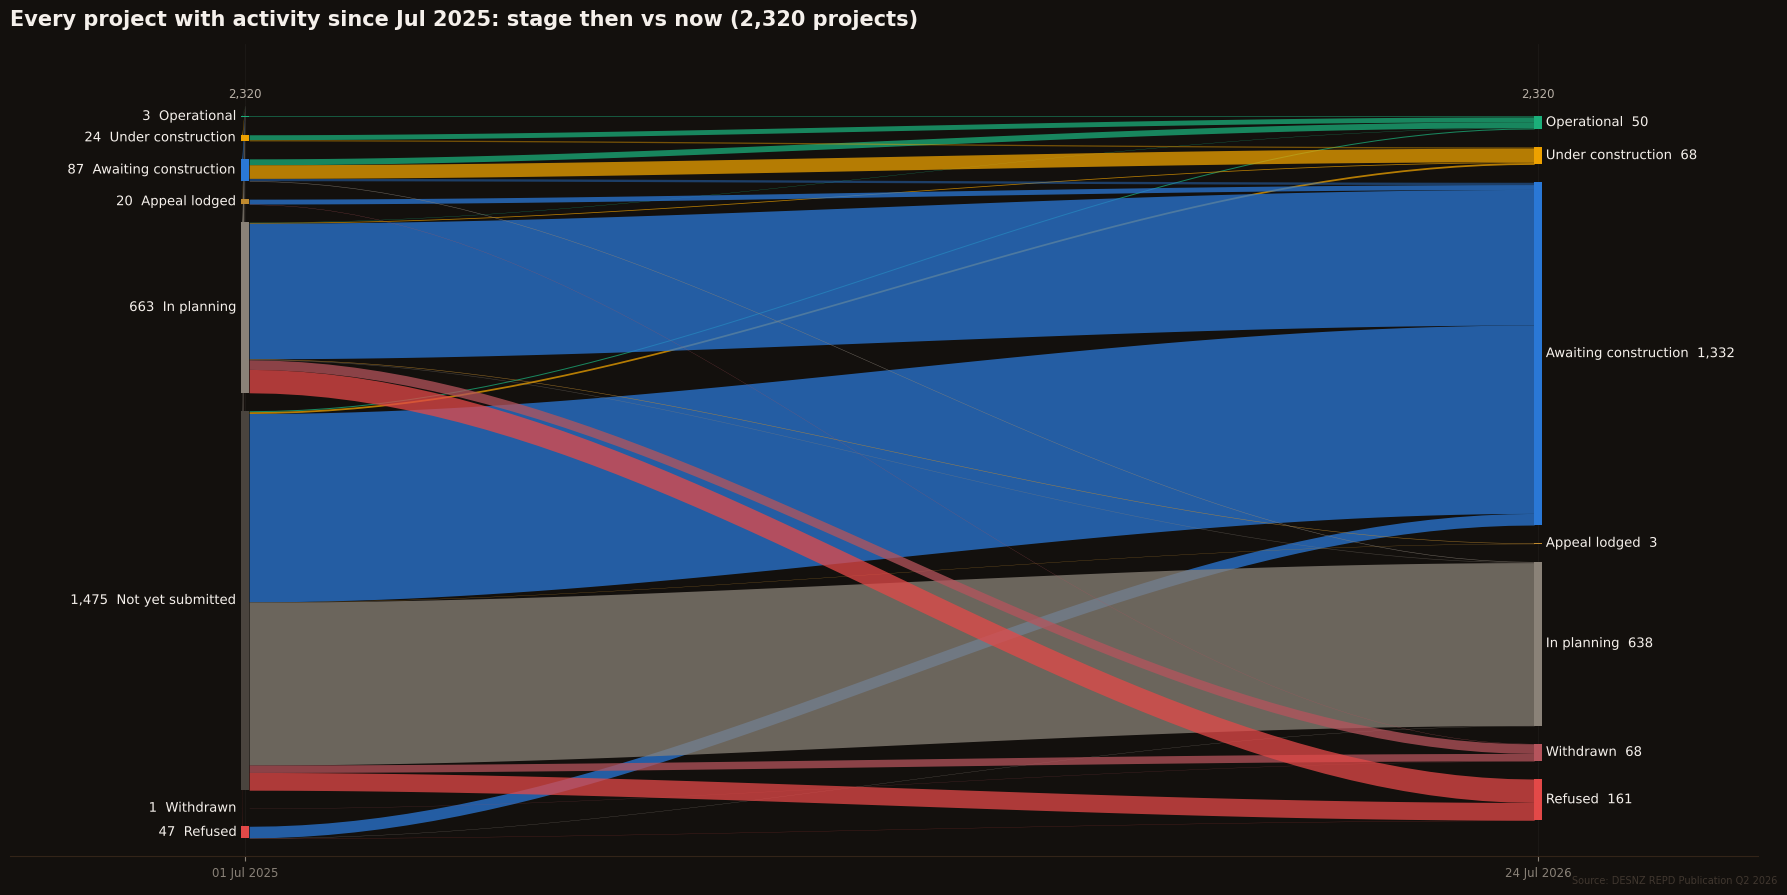

In [4]:
ORDER = ["Operational", "Under construction", "Awaiting construction", "Appeal lodged", "In planning",
         "Not yet submitted", "Withdrawn", "Refused"]
COLORS = {
    "Not yet submitted": "#4a443e", "In planning": "#8a8278", "Appeal lodged": "#c08a2e",
    "Awaiting construction": "#2a78d6", "Under construction": "#eda100", "Operational": "#1baf7a",
    "Refused": "#e34948", "Withdrawn": "#b5545c",
}

fig = plot_alluvial(
    states,
    order=ORDER,
    colors=COLORS,
    title=f"Every project with activity since {SNAPSHOT:%b %Y}: stage then vs now ({len(cohort):,} projects)",
    origin=SNAPSHOT,
    label_first=True,
    credit=f"Source: DESNZ {REPD_CSV.stem.replace('_', ' ')}",
)
fig.savefig("pipeline_full.png", dpi=150, bbox_inches="tight")

## 4. What moved

Projects that changed stage, grouped by the move. Same-stage rows are projects with a dated event in the window that did not change their stage (e.g. a second refusal).

In [5]:
changed = states[states[SNAPSHOT] != states[end]]
print(f"{len(changed):,} of {len(cohort):,} projects changed stage; {len(cohort) - len(changed):,} did not.")
(changed.value_counts()
        .rename_axis([f"{SNAPSHOT:%b %Y}", f"{end:%b %Y}"])
        .rename("projects").to_frame())

2,299 of 2,320 projects changed stage; 21 did not.


projects
Jul 2025              Jul 2026                       
Not yet submitted     Awaiting construction       732
                      In planning                 633
In planning           Awaiting construction       527
                      Refused                      91
Not yet submitted     Refused                      69
Awaiting construction Under construction           53
Refused               Awaiting construction        45
In planning           Withdrawn                    37
Not yet submitted     Withdrawn                    29
Awaiting construction Operational                  23
Under construction    Operational                  19
Appeal lodged         Awaiting construction        19
Not yet submitted     Under construction            7
                      Operational                   4
In planning           Under construction            3
                      Appeal lodged                 2
Awaiting construction In planning                   2
Appeal lodged         Withdrawn                     1
Refused               In planning                   1
In planning           Operational                   1
Not yet submitted     Appeal lodged                 1

**Reading it:** the left column is where each project stood on 1 Jul 2025, the right where it stands now. Refused → Awaiting construction is a refusal overturned on appeal; Awaiting construction → In planning is a resubmission. REPD records decisions with a lag, so the most recent moves are under-counted.